# Uncertainty qunatification

To understand whether the MACE model predicts with certainty in all frames the exact physical quantities or it did not learn completely and it throws random guesses we train three models with different seeds and see how the prediction differs on the same set of frames.

In [ ]:
import os
import numpy as np
from ase.io import read, write
from google.colab import drive

drive.mount('/content/drive')

outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"

data_dir = "/content/drive/MyDrive/MDProject/new_data/1.NVT_300/A.1_10K/UncQuant"
os.makedirs(data_dir, exist_ok=True)

train_file = f"{data_dir}/train.extxyz"
valid_file = f"{data_dir}/valid.extxyz"
test_file = f"{data_dir}/test.extxyz"

print("Reading and subsampling OUTCAR...")
frames = read(outcar_file, index="6840::5", format="vasp-out")
print(f"Extracted {len(frames)} distinct frames.")

# Randomize the order to prevent data leakage across splits
np.random.seed(42) # For reproducibility
np.random.shuffle(frames)

# FIX ASE KEYS
print("Renaming ASE internal keys...")
for frame in frames:
    if 'energy' in frame.info:
        frame.info['REF_energy'] = frame.info.pop('energy')
    if 'stress' in frame.info:
        frame.info['REF_stress'] = frame.info.pop('stress')
    if 'forces' in frame.arrays:
        frame.arrays['REF_forces'] = frame.arrays.pop('forces')

# SPLIT: 80% Train, 10% Valid, 10% Test
n_total = len(frames)
n_train = int(0.8 * n_total)
n_valid = int(0.1 * n_total)

train_frames = frames[:n_train]
valid_frames = frames[n_train : n_train + n_valid]
test_frames = frames[n_train + n_valid:]

# SAVE
write(train_file, train_frames, format="extxyz")
write(valid_file, valid_frames, format="extxyz")
write(test_file, test_frames, format="extxyz")

print(f"Saved {len(train_frames)} train, {len(valid_frames)} valid, and {len(test_frames)} test frames.")

Mounted at /content/drive
Reading and subsampling OUTCAR...
Extracted 632 distinct frames.
Renaming ASE internal keys...
Saved 505 train, 63 valid, and 64 test frames.


Traning: seed 1

In [ ]:
import sys
from mace.cli.run_train import main as mace_train_main

# 1. Define your Google Drive paths
my_train_file = "/content/drive/MyDrive/MDProject/new_data/1.NVT_300/A.1_10K/UncQuant/train.extxyz"
my_valid_file = "/content/drive/MyDrive/MDProject/new_data/1.NVT_300/A.1_10K/UncQuant/valid.extxyz"
my_sim_checkpoints_dir = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed1"
my_sim_results_dir = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/results/seed1"
my_atomic_numbers = "[1, 6, 7, 50, 53]"

custom_args = [
    "mace_run_training",
    "--name=model_3000_pts_seed1",
    "--seed=1",

    f"--train_file={my_train_file}",
    f"--valid_file={my_valid_file}",
    f"--checkpoints_dir={my_sim_checkpoints_dir}",
    f"--results_dir={my_sim_results_dir}",

    "--energy_key=energy",
    "--forces_key=forces",
    "--stress_key=stress",

    "--E0s=foundation",
    "--stress_weight=1.0",
    "--compute_stress=True",

    "--max_num_epochs=50",
    "--patience=10",
    "--batch_size=5",
    "--valid_batch_size=5",
    "--device=cuda",
    "--default_dtype=float32",

    "--r_max=5.0",

    "--keep_checkpoints",

    "--num_channels=64",
    "--max_L=0",
    "--seed=1",

    "--foundation_model=small",
    "--multiheads_finetuning=True",
    "--pt_train_file=mp",

    f"--atomic_numbers={my_atomic_numbers}",
    "--num_samples_pt=1000",
    "--lr=0.0001",

    "--energy_weight=1.0",
    "--forces_weight=100.0",

    # OPTIMIZER
    "--optimizer=adamw",
    "--amsgrad",
    "--weight_decay=5e-7",

    # EMA/SWA
    "--ema",
    "--ema_decay=0.99",

    "--swa",
    "--start_swa=30",

    "--swa_forces_weight=100.0",
    "--swa_stress_weight=1.0",
    "--swa_energy_weight=1.0",

    # SCALING
    "--scaling=rms_forces_scaling"
]

sys.argv = custom_args
mace_train_main()

INFO:root:===========VERIFYING SETTINGS===========


2026-09-23 10:59:49.497 INFO: ===========VERIFYING SETTINGS===========
2026-09-23 10:59:49.497 INFO: ===========VERIFYING SETTINGS===========


INFO:root:Stage Two is activated as start_stage_two was defined


2026-09-23 10:59:49.500 INFO: Stage Two is activated as start_stage_two was defined
2026-09-23 10:59:49.500 INFO: Stage Two is activated as start_stage_two was defined


INFO:root:MACE version: 0.3.16


...

2026-09-23 11:44:19.908 INFO: Skipping evaluation of valid_pt_head (in skip_heads list)
2026-09-23 11:44:19.908 INFO: Skipping evaluation of valid_pt_head (in skip_heads list)


INFO:root:Error-table on TRAIN and VALID:
+---------------+---------------------+------------------+-------------------+---------------------------------------+
|  config_type  | RMSE E / meV / atom | RMSE F / meV / A | relative F RMSE % | RMSE Stress (Virials) / meV / A (A^3) |
+---------------+---------------------+------------------+-------------------+---------------------------------------+
| train_Default |            0.8      |         40.1     |         11.85     |                     5.3               |
| valid_Default |            0.8      |         40.7     |         11.98     |                     5.2               |
+---------------+---------------------+------------------+-------------------+---------------------------------------+


2026-09-23 11:44:19.913 INFO: Error-table on TRAIN and VALID:
+---------------+---------------------+------------------+-------------------+---------------------------------------+
|  config_type  | RMSE E / meV / atom | RMSE F / meV / A | relative F RMSE % | RMSE Stress (Virials) / meV / A (A^3) |
+---------------+---------------------+------------------+-------------------+---------------------------------------+
| train_Default |            0.8      |         40.1     |         11.85     |                     5.3               |
| valid_Default |            0.8      |         40.7     |         11.98     |                     5.2               |
+---------------+---------------------+------------------+-------------------+---------------------------------------+
2026-09-23 11:44:19.913 INFO: Error-table on TRAIN and VALID:
+---------------+---------------------+------------------+-------------------+---------------------------------------+
|  config_type  | RMSE E / meV / atom | RMS

DEBUG:root:Running inference on train_Default dataset
DEBUG:root:Running inference on train_pt_head dataset
DEBUG:root:Running inference on valid_pt_head dataset
DEBUG:root:Running inference on valid_Default dataset
INFO:root:Done


2026-09-23 11:44:54.826 INFO: Done
2026-09-23 11:44:54.826 INFO: Done


Training: seed 2

In [ ]:
import sys
from mace.cli.run_train import main as mace_train_main

my_train_file = "/content/drive/MyDrive/MDProject/new_data/1.NVT_300/A.1_10K/UncQuant/train.extxyz"
my_valid_file = "/content/drive/MyDrive/MDProject/new_data/1.NVT_300/A.1_10K/UncQuant/valid.extxyz"
my_sim_checkpoints_dir = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed2"
my_sim_results_dir = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/results/seed2"
my_atomic_numbers = "[1, 6, 7, 50, 53]"

custom_args = [
    "mace_run_training",
    "--name=model_3000_pts_seed2",
    "--seed=2",

    f"--train_file={my_train_file}",
    f"--valid_file={my_valid_file}",
    f"--checkpoints_dir={my_sim_checkpoints_dir}",
    f"--results_dir={my_sim_results_dir}",

    "--energy_key=energy",
    "--forces_key=forces",
    "--stress_key=stress",

    "--E0s=foundation",
    "--stress_weight=1.0",
    "--compute_stress=True",

    "--max_num_epochs=50",
    "--patience=10",
    "--batch_size=5",
    "--valid_batch_size=5",
    "--device=cuda",
    "--default_dtype=float32",

    "--r_max=5.0",

    "--keep_checkpoints",

    "--num_channels=64",
    "--max_L=0",
    "--seed=1",

    "--foundation_model=small",
    "--multiheads_finetuning=True",
    "--pt_train_file=mp",

    f"--atomic_numbers={my_atomic_numbers}",
    "--num_samples_pt=1000",
    "--lr=0.0001",

    "--energy_weight=1.0",
    "--forces_weight=100.0",

    # OPTIMIZER
    "--optimizer=adamw",
    "--amsgrad",
    "--weight_decay=5e-7",

    # EMA/SWA
    "--ema",
    "--ema_decay=0.99",

    "--swa",
    "--start_swa=30",

    "--swa_forces_weight=100.0",
    "--swa_stress_weight=1.0",
    "--swa_energy_weight=1.0",

    # SCALING
    "--scaling=rms_forces_scaling"
]

sys.argv = custom_args
mace_train_main()

INFO:root:===========VERIFYING SETTINGS===========


2026-09-23 09:20:27.683 INFO: ===========VERIFYING SETTINGS===========
2026-09-23 09:20:27.683 INFO: ===========VERIFYING SETTINGS===========
2026-09-23 09:20:27.683 INFO: ===========VERIFYING SETTINGS===========
2026-09-23 09:20:27.683 INFO: ===========VERIFYING SETTINGS===========


INFO:root:Stage Two is activated as start_stage_two was defined


2026-09-23 09:20:27.688 INFO: Stage Two is activated as start_stage_two was defined
2026-09-23 09:20:27.688 INFO: Stage Two is activated as start_stage_two was defined
2026-09-23 09:20:27.688 INFO: Stage Two is activated as start_stage_two was defined
2026-09-23 09:20:27.688 INFO: Stage Two is activated as start_stage_two was defined


INFO:root:MACE version: 0.3.16


...

2026-09-23 10:05:13.472 INFO: Skipping evaluation of valid_pt_head (in skip_heads list)
2026-09-23 10:05:13.472 INFO: Skipping evaluation of valid_pt_head (in skip_heads list)
2026-09-23 10:05:13.472 INFO: Skipping evaluation of valid_pt_head (in skip_heads list)
2026-09-23 10:05:13.472 INFO: Skipping evaluation of valid_pt_head (in skip_heads list)


INFO:root:Error-table on TRAIN and VALID:
+---------------+---------------------+------------------+-------------------+---------------------------------------+
|  config_type  | RMSE E / meV / atom | RMSE F / meV / A | relative F RMSE % | RMSE Stress (Virials) / meV / A (A^3) |
+---------------+---------------------+------------------+-------------------+---------------------------------------+
| train_Default |            0.8      |         40.2     |         11.86     |                     5.1               |
| valid_Default |            0.8      |         40.8     |         12.00     |                     5.0               |
+---------------+---------------------+------------------+-------------------+---------------------------------------+


2026-09-23 10:05:13.480 INFO: Error-table on TRAIN and VALID:
+---------------+---------------------+------------------+-------------------+---------------------------------------+
|  config_type  | RMSE E / meV / atom | RMSE F / meV / A | relative F RMSE % | RMSE Stress (Virials) / meV / A (A^3) |
+---------------+---------------------+------------------+-------------------+---------------------------------------+
| train_Default |            0.8      |         40.2     |         11.86     |                     5.1               |
| valid_Default |            0.8      |         40.8     |         12.00     |                     5.0               |
+---------------+---------------------+------------------+-------------------+---------------------------------------+
2026-09-23 10:05:13.480 INFO: Error-table on TRAIN and VALID:
+---------------+---------------------+------------------+-------------------+---------------------------------------+
|  config_type  | RMSE E / meV / atom | RMS

DEBUG:root:Running inference on train_Default dataset
DEBUG:root:Running inference on train_pt_head dataset
DEBUG:root:Running inference on valid_pt_head dataset
DEBUG:root:Running inference on valid_Default dataset
INFO:root:Done


2026-09-23 10:05:47.106 INFO: Done
2026-09-23 10:05:47.106 INFO: Done
2026-09-23 10:05:47.106 INFO: Done
2026-09-23 10:05:47.106 INFO: Done


Training: seed 3

In [ ]:
import sys
from mace.cli.run_train import main as mace_train_main

my_train_file = "/content/drive/MyDrive/MDProject/new_data/1.NVT_300/A.1_10K/train.extxyz"
my_valid_file = "/content/drive/MyDrive/MDProject/new_data/1.NVT_300/A.1_10K/valid.extxyz"
my_sim_checkpoints_dir = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed3"
my_sim_results_dir = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/results/seed3"
my_atomic_numbers = "[1, 6, 7, 50, 53]"

custom_args = [
    "mace_run_training",
    "--name=model_3000_pts_seed3",
    "--seed=3",

    f"--train_file={my_train_file}",
    f"--valid_file={my_valid_file}",
    f"--checkpoints_dir={my_sim_checkpoints_dir}",
    f"--results_dir={my_sim_results_dir}",

    "--energy_key=energy",
    "--forces_key=forces",
    "--stress_key=stress",

    "--E0s=foundation",
    "--stress_weight=1.0",
    "--compute_stress=True",

    "--max_num_epochs=50",
    "--patience=10",
    "--batch_size=5",
    "--valid_batch_size=5",
    "--device=cuda",
    "--default_dtype=float32",

    "--r_max=5.0",

    "--keep_checkpoints",

    "--num_channels=64",
    "--max_L=0",
    "--seed=1",

    "--foundation_model=small",
    "--multiheads_finetuning=True",
    "--pt_train_file=mp",

    f"--atomic_numbers={my_atomic_numbers}",
    "--num_samples_pt=1000",
    "--lr=0.0001",

    "--energy_weight=1.0",
    "--forces_weight=100.0",

    # OPTIMIZER
    "--optimizer=adamw",
    "--amsgrad",
    "--weight_decay=5e-7",

    # EMA/SWA
    "--ema",
    "--ema_decay=0.99",

    "--swa",
    "--start_swa=30",

    "--swa_forces_weight=100.0",
    "--swa_stress_weight=1.0",
    "--swa_energy_weight=1.0",

    # SCALING
    "--scaling=rms_forces_scaling"
]

# 3. Run the training
sys.argv = custom_args
mace_train_main()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading OUTCAR (extracting every 10th frame)...
Loaded 1000 frames for UQ analysis.
Loading MACE committee...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Running Uncertainty Quantification...
Processed frame 0/1000 | Mean Uncertainty: 0.55 meV/A
Processed frame 50/1000 | Mean Uncertainty: 0.66 meV/A
Processed frame 100/1000 | Mean Uncertainty: 1.23 meV/A
Processed frame 150/1000 | Mean Uncertainty: 1.26 meV/A
Processed frame 200/1000 | Mean Uncertainty: 0.74 meV/A
Processed frame 250/1000 | Mean Uncertainty: 1.07 meV/A
Processed frame 300/1000 | Mean Uncertainty: 0.71 meV/A
Processed frame 350/1000 | Mean Uncertainty: 0.89 meV/A
Processed frame 400/1000 | Mean Uncertainty: 0.85 meV/A
Processed frame 450/1000 | Mean Uncertainty: 0.73 meV/A
Processed frame 500/1000 | Mean Uncertainty: 0.78 meV/A
Processed frame 550/1000 | Mean Uncertainty: 0.96 meV/A
Processed frame 600/1000 | Mean Uncertainty: 0.95 meV/A
Processed frame 650/1000 | Mean Uncertainty: 0.86 meV/A
Processed frame 700/1000 | Mean Uncertainty: 0.73 meV/A
Processed frame 750/1000 | Mean Uncertainty: 0.77 meV/A
Processed frame 800/1000 | Mean Uncertainty: 0.70 meV/A
Processed fra

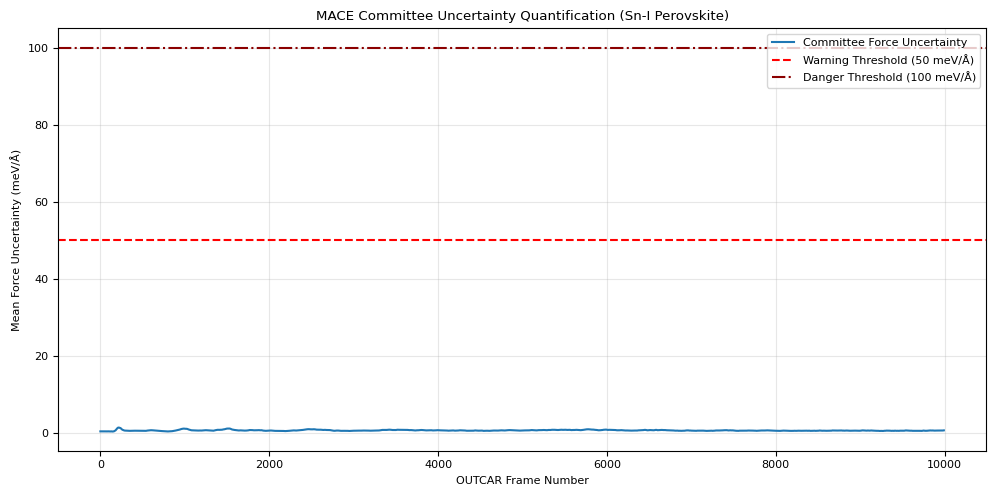

Analysis complete! High-res plot saved to /content/mace_uq_analysis.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from mace.calculators import MACECalculator
from google.colab import drive

drive.mount('/content/drive')

outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"

# Point these to your three compiled committee models
model_1 = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed1/model_3000_pts_seed1_run-1_stagetwo.model"
model_2 = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed2/model_3000_pts_seed2_run-1_stagetwo.model"
model_3 = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed3/model_3000_pts_seed3_run-1_stagetwo.model"

frames = read(outcar_file, index="::10", format="vasp-out")
print(f"Loaded {len(frames)} frames for UQ analysis.")

calc1 = MACECalculator(model_paths=model_1, device='cuda', default_dtype='float32')
calc2 = MACECalculator(model_paths=model_2, device='cuda', default_dtype='float32')
calc3 = MACECalculator(model_paths=model_3, device='cuda', default_dtype='float32')

uncertainties = []

for i, atoms in enumerate(frames):
    # Get forces from Model 1
    atoms.calc = calc1
    f1 = atoms.get_forces()

    # Get forces from Model 2
    atoms.calc = calc2
    f2 = atoms.get_forces()

    # Get forces from Model 3
    atoms.calc = calc3
    f3 = atoms.get_forces()

    # Calculate standard deviation across the 3 models for each atom & component
    f_stack = np.array([f1, f2, f3])
    f_std = np.std(f_stack, axis=0)  # Shape: (num_atoms, 3)

    # Average uncertainty for this frame (converted to meV/A)
    mean_frame_uncertainty = np.mean(f_std) * 1000
    uncertainties.append(mean_frame_uncertainty)

    if i % 50 == 0:
        print(f"Processed frame {i}/{len(frames)} | Mean Uncertainty: {mean_frame_uncertainty:.2f} meV/A")

# Plot the UQ Results
plt.figure(figsize=(10, 5))
# Multiply x-axis by 10 to map back to actual OUTCAR step numbers
plt.plot(np.arange(len(uncertainties)) * 10, uncertainties, label='Committee Force Uncertainty', color='#1f77b4')

plt.xlabel('OUTCAR Frame Number')
plt.ylabel('Mean Force Uncertainty (meV/Å)')
plt.title('MACE Committee Uncertainty Quantification (Sn-I Perovskite)')

# Add a safety threshold line
plt.axhline(y=50, color='r', linestyle='--', label='Warning Threshold (50 meV/Å)')
plt.axhline(y=100, color='darkred', linestyle='-.', label='Danger Threshold (100 meV/Å)')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save and show
plt.savefig('/content/mace_uq_analysis.png', dpi=300)
plt.show()

print("Analysis complete! High-res plot saved to /content/mace_uq_analysis.png")

Making the analysis more general, averaging out the indicator and inspecting more physical quantities

/usr/local/lib/python3.13/dist-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Mounted at /content/drive
Loading OUTCAR (extracting every 10th frame)...
Loaded 1000 frames for UQ analysis.
Loading MACE committee...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Running Uncertainty Quantification...
Frame 0    | Force UQ:   0.5 meV/A | Energy UQ:  0.05 meV/atom
Frame 50   | Force UQ:   0.7 meV/A | Energy UQ:  0.05 meV/atom
Frame 100  | Force UQ:   1.2 meV/A | Energy UQ:  0.01 meV/atom
Frame 150  | Force UQ:   1.3 meV/A | Energy UQ:  0.11 meV/atom
Frame 200  | Force UQ:   0.7 meV/A | Energy UQ:  0.04 meV/atom
Frame 250  | Force UQ:   1.1 meV/A | Energy UQ:  0.05 meV/atom
Frame 300  | Force UQ:   0.7 meV/A | Energy UQ:  0.04 meV/atom
Frame 350  | Force UQ:   0.9 meV/A | Energy UQ:  0.05 meV/atom
Frame 400  | Force UQ:   0.8 meV/A | Energy UQ:  0.06 meV/atom
Frame 450  | Force UQ:   0.7 meV/A | Energy UQ:  0.03 meV/atom
Frame 500  | Force UQ:   0.8 meV/A | Energy UQ:  0.03 meV/atom
Frame 550  | Force UQ:   1.0 meV/A | Energy UQ:  0.03 meV/atom
Frame 600  | Force UQ:   1.0 meV/A | Energy UQ:  0.04 meV/atom
Frame 650  | Force UQ:   0.9 meV/A | Energy UQ:  0.05 meV/atom
Frame 700  | Force UQ:   0.7 meV/A | Energy UQ:  0.03 meV/atom
Frame 750  | Forc

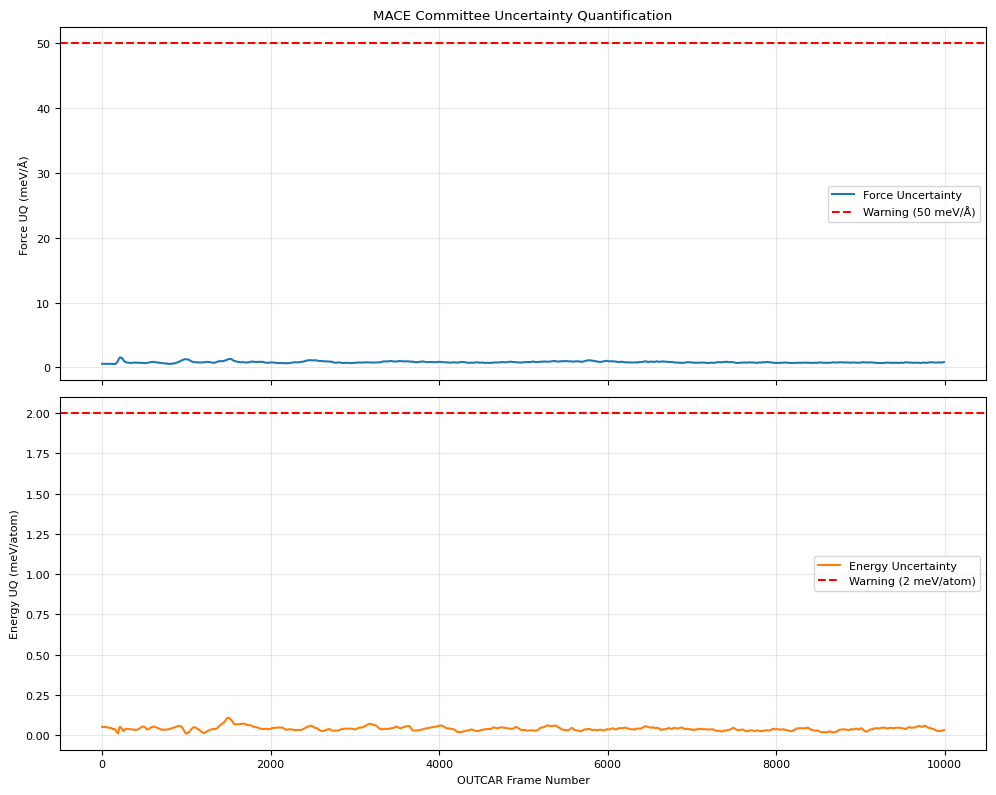

Analysis complete! High-res plots saved to /content/mace_uq_comprehensive.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from mace.calculators import MACECalculator
from google.colab import drive

drive.mount('/content/drive')

outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"

model_1 = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed1/model_3000_pts_seed1_run-1_stagetwo.model"
model_2 = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed2/model_3000_pts_seed2_run-1_stagetwo.model"
model_3 = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed3/model_3000_pts_seed3_run-1_stagetwo.model"

print("Loading OUTCAR (extracting every 10th frame)...")
frames = read(outcar_file, index="::10", format="vasp-out")
print(f"Loaded {len(frames)} frames for UQ analysis.")

calc1 = MACECalculator(model_paths=model_1, device='cuda', default_dtype='float32')
calc2 = MACECalculator(model_paths=model_2, device='cuda', default_dtype='float32')
calc3 = MACECalculator(model_paths=model_3, device='cuda', default_dtype='float32')

uncert_forces = []
uncert_energies = []
uncert_stress = []

print("Running Uncertainty Quantification...")
for i, atoms in enumerate(frames):
    num_atoms = len(atoms)

    # --- MODEL 1 ---
    atoms.calc = calc1
    e1 = atoms.get_potential_energy()
    f1 = atoms.get_forces()
    s1 = atoms.get_stress()

    # --- MODEL 2 ---
    atoms.calc = calc2
    e2 = atoms.get_potential_energy()
    f2 = atoms.get_forces()
    s2 = atoms.get_stress()

    # --- MODEL 3 ---
    atoms.calc = calc3
    e3 = atoms.get_potential_energy()
    f3 = atoms.get_forces()
    s3 = atoms.get_stress()


    #  Force Uncertainty
    f_std = np.std([f1, f2, f3], axis=0)
    mean_f_uncert = np.mean(f_std) * 1000 # Convert to meV/A
    uncert_forces.append(mean_f_uncert)

    # Energy Uncertainty
    e_std = np.std([e1, e2, e3])
    mean_e_uncert = (e_std / num_atoms) * 1000 # Convert to meV/atom
    uncert_energies.append(mean_e_uncert)

    # Stress Uncertainty
    s_std = np.std([s1, s2, s3], axis=0)
    mean_s_uncert = np.mean(s_std) * 1000 # Convert to meV/A^3
    uncert_stress.append(mean_s_uncert)

    if i % 50 == 0:
        print(f"Frame {i:<4} | Force UQ: {mean_f_uncert:>5.1f} meV/A | Energy UQ: {mean_e_uncert:>5.2f} meV/atom")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
x_axis = np.arange(len(uncert_forces)) * 10 # Map back to true OUTCAR steps


ax1.plot(x_axis, uncert_forces, label='Force Uncertainty', color='#1f77b4')
ax1.axhline(y=50, color='r', linestyle='--', label='Warning (50 meV/Å)')
ax1.set_ylabel('Force UQ (meV/Å)')
ax1.set_title('MACE Committee Uncertainty Quantification')
ax1.legend()
ax1.grid(True, alpha=0.3)


ax2.plot(x_axis, uncert_energies, label='Energy Uncertainty', color='#ff7f0e')
ax2.axhline(y=2.0, color='r', linestyle='--', label='Warning (2 meV/atom)')
ax2.set_xlabel('OUTCAR Frame Number')
ax2.set_ylabel('Energy UQ (meV/atom)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/mace_uq_comprehensive.png', dpi=300)
plt.show()

print("Analysis complete! High-res plots saved to /content/mace_uq_comprehensive.png")

Upload of needed libraries

In [ ]:
! pip install pymbar
! pip install ase
! pip install mace-torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.4/107.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 53.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.0/316.0 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 387.7/387.7 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 222.8/222.8 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 346.8/346.8 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 453.1/453.1 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 41.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 4.0 MB/s eta 0:00:00
  Created wheel for python-hostlist: filename=python_hostlist-2.3.0-py3-none-any.whl size=39523 sha256=039c024d0c569fc84ce4058eb1f6abfa37d485819f9c7ff02c668ff6993e2d4a
  Stored in directory: /root/.cache/pip/wheels/05/2e/7e/39f980a5a0755f